In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/pesticides.csv')

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset Shape: (4349, 7)
           Domain     Area Element                Item  Year  \
0  Pesticides Use  Albania     Use  Pesticides (total)  1990   
1  Pesticides Use  Albania     Use  Pesticides (total)  1991   
2  Pesticides Use  Albania     Use  Pesticides (total)  1992   
3  Pesticides Use  Albania     Use  Pesticides (total)  1993   
4  Pesticides Use  Albania     Use  Pesticides (total)  1994   

                           Unit  Value  
0  tonnes of active ingredients  121.0  
1  tonnes of active ingredients  121.0  
2  tonnes of active ingredients  121.0  
3  tonnes of active ingredients  121.0  
4  tonnes of active ingredients  201.0  
['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value']


In [3]:
# Remove unnecessary spaces in column names
df.columns = df.columns.str.strip()

# Remove duplicate rows
df = df.drop_duplicates()

# Handle missing values
df = df.dropna(subset=['Value'])

# Separate input and output
X = df.drop('Value', axis=1)
y = df['Value']

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
           Domain     Area Element                Item  Year  \
0  Pesticides Use  Albania     Use  Pesticides (total)  1990   
1  Pesticides Use  Albania     Use  Pesticides (total)  1991   
2  Pesticides Use  Albania     Use  Pesticides (total)  1992   
3  Pesticides Use  Albania     Use  Pesticides (total)  1993   
4  Pesticides Use  Albania     Use  Pesticides (total)  1994   

                           Unit  
0  tonnes of active ingredients  
1  tonnes of active ingredients  
2  tonnes of active ingredients  
3  tonnes of active ingredients  
4  tonnes of active ingredients  

Target Values:
0    121.0
1    121.0
2    121.0
3    121.0
4    201.0
Name: Value, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3479, 6)
Testing data: (870, 6)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_cols = X.select_dtypes(
    include=['object']
).columns

numerical_cols = X.select_dtypes(
    include=['number']
).columns

preprocessor = ColumnTransformer([
    ('categorical',
     Pipeline([
         ('imputer', SimpleImputer(strategy='most_frequent')),
         ('encoder', OneHotEncoder(handle_unknown='ignore'))
     ]),
     categorical_cols),

    ('numerical',
     SimpleImputer(strategy='median'),
     numerical_cols)
])

In [6]:
from sklearn.linear_model import LinearRegression

model1 = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

print("Linear Regression trained successfully!")
print(pred1[:10])

Linear Regression trained successfully!
[11162.66706025 -3475.56584962  2257.67568111  3459.20675443
 -1612.73159043   367.8040696  -1374.75107626  4930.49551395
   192.88562233 11719.7530322 ]


In [7]:
from sklearn.tree import DecisionTreeRegressor

model2 = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)

print("Decision Tree trained successfully!")
print(pred2[:10])

Decision Tree trained successfully!
[1.204763e+04 7.132800e+02 2.955100e+02 1.498240e+03 3.490000e+03
 5.000000e+00 1.091000e+03 4.222400e+02 2.370000e+02 7.345700e+03]


In [8]:
from sklearn.ensemble import RandomForestRegressor

model3 = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model3.fit(X_train, y_train)

pred3 = model3.predict(X_test)

print("Random Forest trained successfully!")
print(pred3[:10])

Random Forest trained successfully!
[1.14268956e+04 7.13280000e+02 3.24235500e+02 1.52382540e+03
 3.48801000e+03 5.23020000e+00 1.18307000e+03 4.22240000e+02
 3.03953100e+02 7.19017300e+03]


In [9]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

results = []

predictions = {
    'Linear Regression': pred1,
    'Decision Tree': pred2,
    'Random Forest': pred3
}

for name, pred in predictions.items():

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print(results_df)

               Model          MAE           MSE          RMSE  R2 Score
0  Linear Regression  7492.402083  1.152519e+09  33948.768168  0.934506
1      Decision Tree  1316.830839  3.600350e+07   6000.291751  0.997954
2      Random Forest   987.958754  1.375883e+07   3709.289548  0.999218


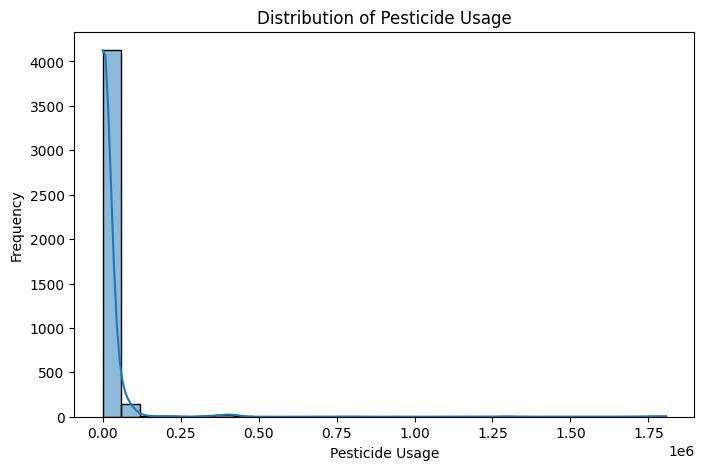

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(df['Value'], bins=30, kde=True)

plt.title("Distribution of Pesticide Usage")
plt.xlabel("Pesticide Usage")
plt.ylabel("Frequency")

plt.show()

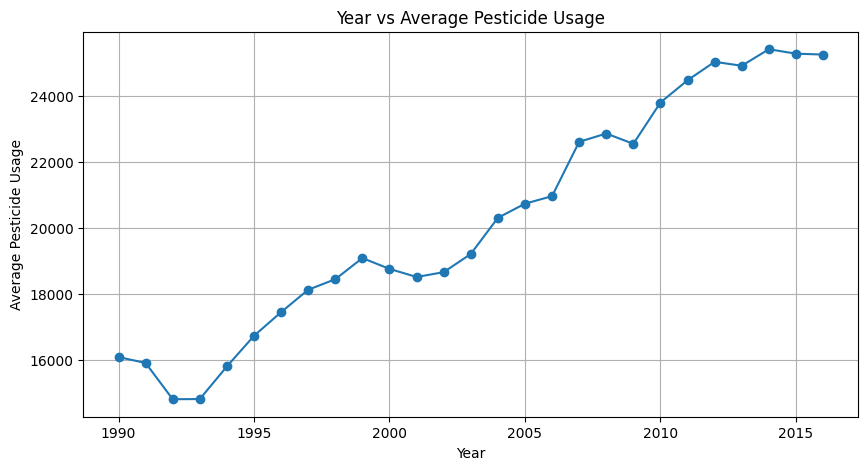

In [11]:
year_usage = df.groupby('Year')['Value'].mean()

plt.figure(figsize=(10,5))

plt.plot(year_usage.index, year_usage.values, marker='o')

plt.title("Year vs Average Pesticide Usage")
plt.xlabel("Year")
plt.ylabel("Average Pesticide Usage")

plt.grid(True)
plt.show()

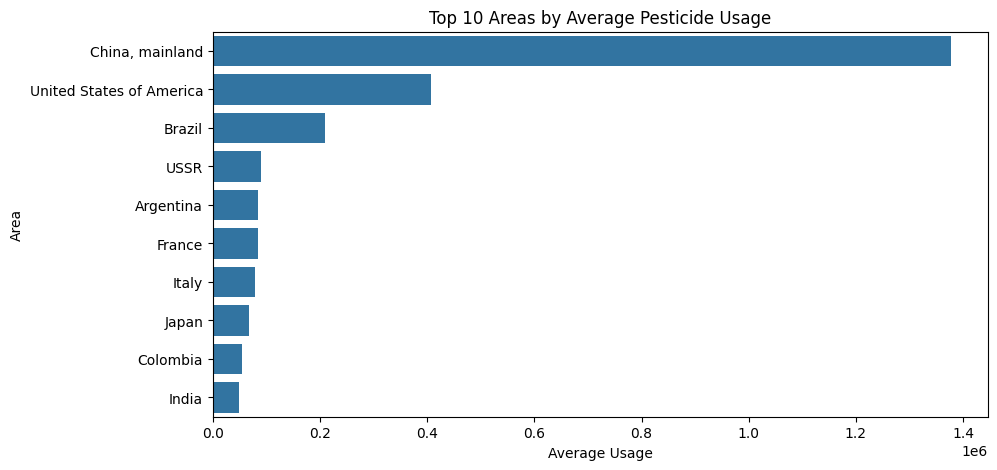

In [12]:
area_usage = (
    df.groupby('Area')['Value']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))

sns.barplot(x=area_usage.values, y=area_usage.index)

plt.title("Top 10 Areas by Average Pesticide Usage")
plt.xlabel("Average Usage")
plt.ylabel("Area")

plt.show()

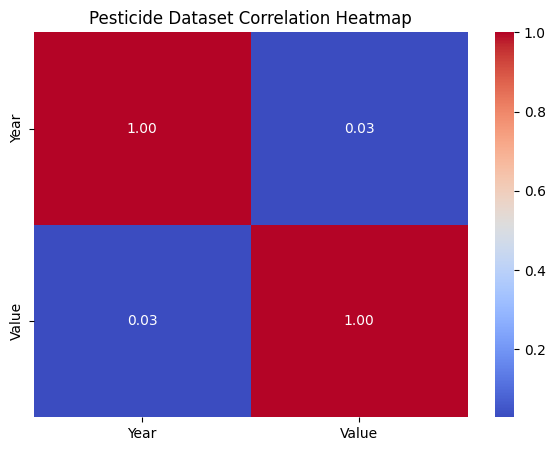

In [13]:
plt.figure(figsize=(7,5))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Pesticide Dataset Correlation Heatmap")
plt.show()

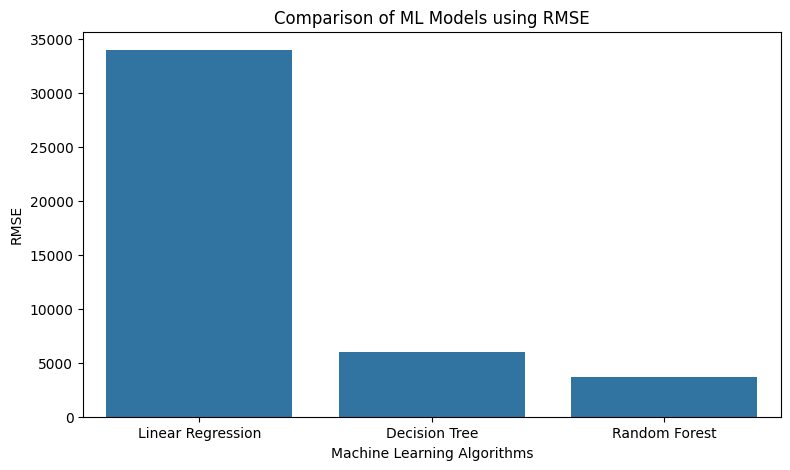

In [14]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("Comparison of ML Models using RMSE")
plt.ylabel("RMSE")
plt.xlabel("Machine Learning Algorithms")

plt.show()

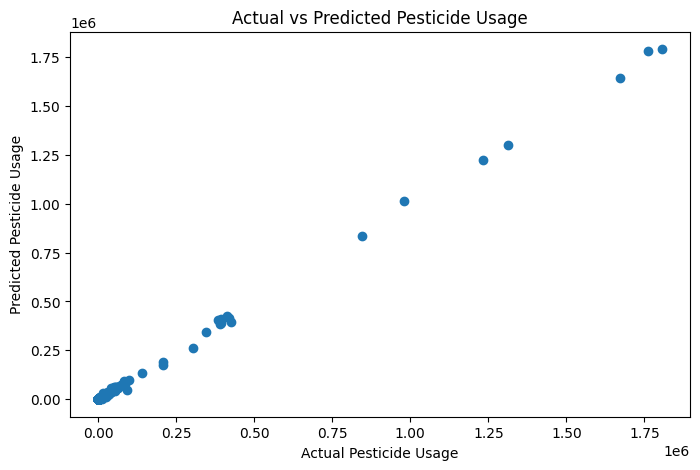

In [15]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, pred3)

plt.xlabel("Actual Pesticide Usage")
plt.ylabel("Predicted Pesticide Usage")

plt.title("Actual vs Predicted Pesticide Usage")

plt.show()